# Sector & Regional Representativeness Analysis
### Greek SME Registry (ΓΕΜΗ) — 250k-Firm Metadata Sample

**Purpose.** This notebook supports Section 5.5 of the thesis ("External Validity:
Sector and Regional Representativeness"). It uses registry *metadata only* for the
population of financial-statement-obligated Greek companies, to:

1. Describe the population by legal form, status, region, sector, and firm age.
2. Quantify the panel-eligibility funnel: obligated firms (~228k) -> firms with 10
   consecutive years of filings (~3,900) -> 2,000 randomly sampled firms (the primary
   thesis panel).
3. Compare distributions **across all three stages of that funnel** (not just
   population vs. final panel) to argue directly against selection bias in the random
   2,000-firm draw.

Changes from the previous version: the branch-establishment chart is dropped
(`isBranch` is ~0% across the board in the real data -- not a bug, just an
uninformative field here); the auto-registration-over-time chart is dropped for the
same reason (`autoRegistered` is essentially always `False`); a company-status chart
(active / deleted / dissolved / etc.) is added in its place; the funnel comparison in
Section 12 now runs across all three sample stages; and every chart uses one
coordinated colour system instead of the previous ad hoc palette.

## 1. Setup & Configuration

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from datetime import datetime

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
TODAY = pd.Timestamp("2026-09-13")

# ---- Configuration ----
USE_SYNTHETIC = False  # confirmed real file: gemi_coverage_summary.csv
RAW_CSV = "gemi_coverage_summary.csv"
PRIMARY_PANEL_CSV = "gemi_dataset_2k_final_v4.csv"

# ---- Visual style ----
plt.rcParams.update({
    "figure.dpi": 120,
    "font.family": "Carlito",       # clean, modern, full Greek glyph coverage
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlepad": 14,
    "axes.titlecolor": "#14304F",   # deep navy titles, on-brand with the palette below
    "axes.labelsize": 10.5,
    "axes.edgecolor": "#5C6F7C",
    "axes.linewidth": 0.8,
    "text.color": "#33424E",
    "axes.labelcolor": "#33424E",
    "xtick.color": "#5C6F7C",
    "ytick.color": "#33424E",
    "legend.fontsize": 10,
})
sns.set_style("white")

print(f"Synthetic mode: {USE_SYNTHETIC}")

Synthetic mode: False


## 2. Colour System & Plotting Helpers

One coordinated, analogous colour family (deep navy through teal to warm gold/coral),
so every chart in the notebook reads as part of the same design rather than each
using a different default palette. `Λοιπά (Other)` and `Άγνωστο` (missing) always get
the same two neutral greys everywhere, so a reader learns once what grey means and
never has to relearn it per chart.

In [3]:
# ---- Coordinated colour system: cool tones only (blues, teals, grey, cool rose) ----
NAVY     = "#14304F"   # deep blue -- primary
TEAL     = "#1F7A72"   # blue-green -- secondary
STEEL    = "#4C7FA6"   # steel blue
SKY      = "#7FA8C9"   # pale steel blue
ROSE     = "#A65C82"   # cool, blue-leaning pink -- the one warm-adjacent accent, kept cool
SLATE    = "#5C6F7C"   # cool blue-grey
DEEPTEAL = "#123D3A"   # near-black teal, for high-contrast accents
GREY     = "#8C97A0"   # neutral cool grey

PALETTE = [NAVY, TEAL, STEEL, ROSE, SLATE, SKY, DEEPTEAL, GREY]
OTHER_GREY   = "#BCC5CC"   # cool, slightly blue-tinted grey
UNKNOWN_GREY = "#DEE3E7"   # very light cool grey
UNKNOWN = "Άγνωστο"
OTHER_LABEL = "Λοιπά (Other)"

# Three-stage funnel colours (population -> eligible pool -> primary panel), used
# consistently in every chart that compares the three sample stages
STAGE_COLORS = {"population": NAVY, "eligible": TEAL, "panel": ROSE}


def style_axis(ax, horizontal=True):
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    if horizontal:
        ax.spines["left"].set_visible(False)
        ax.grid(axis="x", alpha=0.22, linewidth=0.7, color="#888888")
        ax.grid(axis="y", visible=False)
    else:
        ax.spines["left"].set_visible(False)
        ax.grid(axis="y", alpha=0.22, linewidth=0.7, color="#888888")
        ax.grid(axis="x", visible=False)
    ax.tick_params(length=0)


def category_colors(labels):
    """Assigns PALETTE colours to real categories in order, always mapping
    Other/Unknown to the same two neutral greys regardless of position."""
    colors, i = [], 0
    for l in labels:
        if l == OTHER_LABEL:
            colors.append(OTHER_GREY)
        elif l == UNKNOWN:
            colors.append(UNKNOWN_GREY)
        else:
            colors.append(PALETTE[i % len(PALETTE)])
            i += 1
    return colors


def top_n_plus_other(series, n=8, other_label=OTHER_LABEL, fillna_label=UNKNOWN,
                      report=True, name=""):
    """Value counts capped at the top n categories; the rest collapsed into one
    'Other' bucket; missing values shown as an explicit 'Άγνωστο' category rather
    than silently dropped. Prints a one-line note explaining what Άγνωστο means for
    this specific field, since it otherwise looks like an unexplained category."""
    total = len(series)
    n_missing = series.isna().sum()
    if report and n_missing > 0:
        print(f"{name or series.name}: {n_missing:,} missing values ({n_missing/total*100:.1f}%) "
              f"shown as '{UNKNOWN}' below rather than dropped.")
    s = series.fillna(fillna_label).astype(str)
    counts = s.value_counts()
    if len(counts) <= n:
        return counts
    top = counts.iloc[:n].copy()
    other_sum = counts.iloc[n:].sum()
    if other_sum > 0:
        top[other_label] = other_sum
    return top


def barh_pct(counts, title, xlabel="Share of firms (%)", figsize=None, total=None, ax=None):
    total = total if total is not None else counts.sum()
    pct = (counts / total * 100).sort_values(ascending=True)
    fig = None
    if ax is None:
        figsize = figsize or (8, max(2.2, 0.45 * len(pct) + 1))
        fig, ax = plt.subplots(figsize=figsize)
    colors = category_colors(pct.index)
    bars = ax.barh(pct.index, pct.values, color=colors, height=0.62)
    xmax = pct.values.max() if len(pct) else 1
    for b, v in zip(bars, pct.values):
        ax.text(b.get_width() + xmax * 0.015, b.get_y() + b.get_height() / 2,
                 f"{v:.1f}%", va="center", fontsize=9.5, color="#2B2B2B")
    ax.set_xlim(0, xmax * 1.18)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    style_axis(ax, horizontal=True)
    if fig is not None:
        plt.tight_layout()
    return ax


def show_head(df, n=5):
    """Display helper: rows numbered 1..n instead of pandas' default 0-based index,
    since a 1-based 'row 1, row 2, ...' reads more naturally in a thesis appendix."""
    out = df.head(n).copy()
    out.index = range(1, len(out) + 1)
    out.index.name = "#"
    return out


# ---- NACE Rev.2 / ΣΤΑΚΟΔ08 section mapping (2-digit ΚΑΔ prefix -> section) ----
NACE_SECTION_RANGES = [
    (1, 3, "A - Γεωργία, Δασοκομία, Αλιεία"), (5, 9, "B - Ορυχεία, Λατομεία"),
    (10, 33, "C - Μεταποίηση"), (35, 35, "D - Ηλεκτρισμός, Αέριο"),
    (36, 39, "E - Ύδρευση, Διαχ. Αποβλήτων"), (41, 43, "F - Κατασκευές"),
    (45, 47, "G - Χονδρικό/Λιανικό Εμπόριο"), (49, 53, "H - Μεταφορά, Αποθήκευση"),
    (55, 56, "I - Καταλύματα, Εστίαση"), (58, 63, "J - Ενημέρωση, Επικοινωνία"),
    (64, 66, "K - Χρηματοπιστωτικές Δραστ."), (68, 68, "L - Διαχείριση Ακίνητης Περ."),
    (69, 75, "M - Επιστημονικές, Τεχνικές Δραστ."), (77, 82, "N - Διοικητικές, Υποστηρικτικές Δραστ."),
    (84, 84, "O - Δημόσια Διοίκηση"), (85, 85, "P - Εκπαίδευση"),
    (86, 88, "Q - Υγεία, Κοινωνική Μέριμνα"), (90, 93, "R - Τέχνες, Ψυχαγωγία"),
    (94, 96, "S - Λοιπές Υπηρεσίες"), (97, 98, "T - Δραστ. Νοικοκυριών"),
    (99, 99, "U - Ετερόδικοι Οργανισμοί"),
]


def kad_to_nace_section(kad_code):
    try:
        s = str(kad_code).strip().split(".")[0]
        if not s or s.lower() == "nan" or len(s) < 2:
            return UNKNOWN
        prefix = int(s[:2])
    except (ValueError, TypeError):
        return UNKNOWN
    for lo, hi, label in NACE_SECTION_RANGES:
        if lo <= prefix <= hi:
            return label
    return UNKNOWN


ATTICA_MARKERS = ["ΑΤΤΙΚ", "ΑΘΗΝΩΝ", "ΠΕΙΡΑΙ"]

def unify_attica(pref):
    if pd.isna(pref):
        return UNKNOWN
    p = str(pref).upper()
    return "ΑΤΤΙΚΗΣ" if any(m in p for m in ATTICA_MARKERS) else pref


print("Helpers loaded.")

Helpers loaded.


## 3. Data Loading

In [4]:
def generate_synthetic_250k(n=50_000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    legal_types = rng.choice(["ΙΚΕ", "ΕΠΕ", "ΑΕ", "Κοιν.Σ.Επ.", "ΣυνΠΕ", "Συνεταιρισμός"],
                              size=n, p=[0.50, 0.20, 0.20, 0.04, 0.03, 0.03])
    incorp_year = np.empty(n, dtype=int)
    for lt in np.unique(legal_types):
        mask = legal_types == lt
        mode = 2021 if lt == "ΙΚΕ" else 1998
        incorp_year[mask] = rng.triangular(1970, mode, 2025, size=mask.sum()).astype(int)
    incorporation_date = pd.to_datetime(
        [f"{y}-{rng.integers(1,13):02d}-{rng.integers(1,28):02d}" for y in incorp_year])
    prefectures = rng.choice(
        ["ΑΤΤΙΚΗΣ", "ΑΘΗΝΩΝ", "ΠΕΙΡΑΙΩΣ", "ΔΥΤΙΚΗΣ ΑΤΤΙΚΗΣ", "ΑΝΑΤΟΛΙΚΗΣ ΑΤΤΙΚΗΣ",
         "ΘΕΣΣΑΛΟΝΙΚΗΣ", "ΑΧΑΙΑΣ", "ΗΡΑΚΛΕΙΟΥ", "ΛΑΡΙΣΑΣ", "ΙΩΑΝΝΙΝΩΝ", "ΚΑΒΑΛΑΣ", "ΑΛΛΗ"],
        size=n, p=[0.20,0.08,0.05,0.03,0.03,0.14,0.05,0.04,0.03,0.03,0.03,0.29])
    kad_prefix = rng.choice([47,10,41,69,56,49,62,68,86,96], size=n,
                             p=[0.24,0.14,0.11,0.11,0.09,0.07,0.06,0.05,0.04,0.09])
    primary_kad = [f"{p}.{rng.integers(10,99)}" for p in kad_prefix]
    primary_activity = [f"ΔΡΑΣΤΗΡΙΟΤΗΤΑ ΤΥΠΟΥ {p}" for p in kad_prefix]
    status = rng.choice(
        ["Ενεργή", "Διαγραφή", "Λύση - Εκκαθάριση", "Διαγραφή λόγω συγχώνευσης", "Πτώχευση", "Σε Αδράνεια"],
        size=n, p=[0.76, 0.175, 0.047, 0.012, 0.004, 0.002])
    is_branch = rng.choice([True, False], size=n, p=[0.002, 0.998])
    auto_registered = rng.choice([True, False], size=n, p=[0.02, 0.98])
    n_activities = rng.poisson(1.6, size=n).clip(1, None)
    n_persons = rng.poisson(2.3, size=n).clip(1, None)
    n_years_covered = rng.choice(np.arange(1, 11), size=n,
                                  p=[0.28,0.16,0.12,0.10,0.09,0.08,0.06,0.05,0.04,0.02])
    meets_threshold = n_years_covered == 10
    last_status_change = incorporation_date + pd.to_timedelta(rng.integers(30, 3650, size=n), unit="D")
    last_status_change = last_status_change.where(last_status_change <= TODAY, TODAY)

    return pd.DataFrame({
        "arGemi": np.arange(1_000_000, 1_000_000+n), "afm": [f"{rng.integers(1e8,1e9):.0f}" for _ in range(n)],
        "coNameEl": [f"COMPANY_{i}" for i in range(n)], "legalType": legal_types,
        "status": status, "isActive": np.nan, "incorporationDate": incorporation_date,
        "lastStatusChange": last_status_change, "isBranch": is_branch,
        "autoRegistered": auto_registered, "prefecture": prefectures,
        "municipality": [f"MUN_{p}" for p in prefectures], "gemiOffice": [f"GEMI_{p}" for p in prefectures],
        "n_activities": n_activities, "primary_activity": primary_activity, "primary_kad": primary_kad,
        "n_persons": n_persons, "financial_statement_obligated": True,
        "n_years_covered": n_years_covered, "meets_threshold": meets_threshold,
    })


STR_DTYPES = {"arGemi": str, "afm": str, "primary_kad": str, "primary_activity": str}

if USE_SYNTHETIC:
    df250 = generate_synthetic_250k()
    print(f"Generated synthetic population: {df250.shape}")
else:
    df250 = pd.read_csv(RAW_CSV, dtype=STR_DTYPES,
                         parse_dates=["incorporationDate", "lastStatusChange"])
    print(f"Loaded real population: {df250.shape}")

# Unify Attica prefectures FIRST, before any preview, count, or downstream analysis --
# doing this later (after head()/top-N calculations already ran on raw `prefecture`)
# is exactly what caused region rankings to come out wrong (Dodekanisou outranking
# Attica) in an earlier version of this notebook.
df250["region_group"] = df250["prefecture"].apply(unify_attica)
n_attica = df250["prefecture"].astype(str).str.upper().str.contains(
    "|".join(ATTICA_MARKERS), na=False).sum()
print(f"Firms merged into ΑΤΤΙΚΗ: {n_attica:,} ({n_attica/len(df250)*100:.1f}% of the population)")
print(f"Distinct prefecture labels before merge: {df250['prefecture'].nunique()}")
print(f"Distinct region labels after merge: {df250['region_group'].nunique()}")

# show_head(df250)  # raw register rows are not displayed: the data are not redistributed


Loaded real population: (228442, 20)
Firms merged into ΑΤΤΙΚΗ: 123,331 (54.0% of the population)
Distinct prefecture labels before merge: 56
Distinct region labels after merge: 53


## 4. Structural Checks & Missing-Data Diagnosis

In [5]:
print('Shape:', df250.shape)
print('Duplicate arGemi:', df250['arGemi'].duplicated().sum())
print('Duplicate afm:', df250['afm'].duplicated().sum())
print('financial_statement_obligated == True:',
      f"{(df250['financial_statement_obligated'] == True).mean() * 100:.1f}%")
print('\nMissingness by column (%):')
print((df250.isna().mean() * 100).round(2).sort_values(ascending=False))

Shape: (228442, 21)
Duplicate arGemi: 0
Duplicate afm: 418
financial_statement_obligated == True: 100.0%

Missingness by column (%):
isActive                         100.00
primary_activity                   2.12
primary_kad                        2.12
prefecture                         1.32
municipality                       0.97
incorporationDate                  0.03
afm                                0.02
status                             0.01
arGemi                             0.00
legalType                          0.00
coNameEl                           0.00
isBranch                           0.00
lastStatusChange                   0.00
gemiOffice                         0.00
autoRegistered                     0.00
n_activities                       0.00
n_persons                          0.00
financial_statement_obligated      0.00
n_years_covered                    0.00
meets_threshold                    0.00
region_group                       0.00
dtype: float64


In [6]:
print("status value counts (used to verify/derive is_active below):")
print(df250["status"].value_counts(dropna=False))
print()

isactive_missing_pct = df250["isActive"].isna().mean() * 100
print(f"isActive missing: {isactive_missing_pct:.1f}%")
ACTIVE_STATUS_MARKERS = ["ΕΝΕΡΓ"]  # adjust if the status labels above differ

if isactive_missing_pct > 50:
    print("isActive is unusable (>50% missing) -- deriving is_active_derived from `status`.")
    df250["is_active_derived"] = df250["status"].fillna("").astype(str).apply(
        lambda s: any(marker in s.upper() for marker in ACTIVE_STATUS_MARKERS))
    ACTIVE_COL = "is_active_derived"
else:
    ACTIVE_COL = "isActive"

print(f"\nUsing '{ACTIVE_COL}' as the active-firm indicator. Share active: {df250[ACTIVE_COL].mean()*100:.1f}%")

status value counts (used to verify/derive is_active below):
status
Ενεργή                       173704
Διαγραφή                      39981
Λύση - Εκκαθάριση             10730
Διαγραφή λόγω συγχώνευσης      2700
Πτώχευση                        924
Άλλο                             95
Διαγραφή λόγω διάσπασης          92
Σε Αδράνεια                      88
Αναστολή καταχώρησης             57
Διαδικασία Συνδιαλλαγής          50
NaN                              15
Αναγκαστική διαχείριση            5
Προεγγραφή                        1
Name: count, dtype: int64

isActive missing: 100.0%
isActive is unusable (>50% missing) -- deriving is_active_derived from `status`.

Using 'is_active_derived' as the active-firm indicator. Share active: 76.0%


## 5. Legal-Form Distribution

,count,pct
legalType,,
ΙΚΕ,132989,58.2
ΑΕ,56573,24.8
ΕΠΕ,33646,14.7
Κοιν.Σ.Επ.,2439,1.1
Ενεργειακή Κοινότητα,1436,0.6
ΣυνΠΕ,867,0.4
Λοιπά (Other),492,0.2


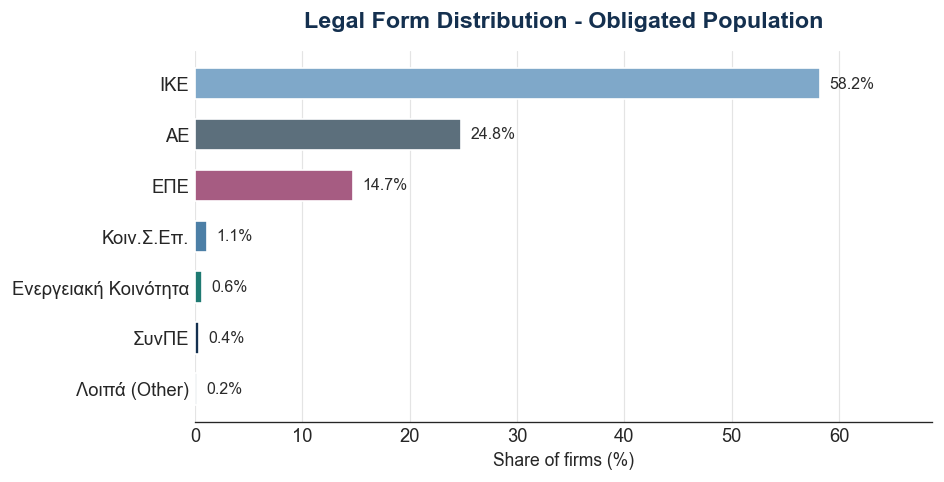

In [7]:
legal_top = top_n_plus_other(df250["legalType"], n=6, name="legalType")
display(legal_top.to_frame("count").assign(pct=lambda d: (d['count']/len(df250)*100).round(1)))

barh_pct(legal_top, "Legal Form Distribution - Obligated Population")
plt.show()

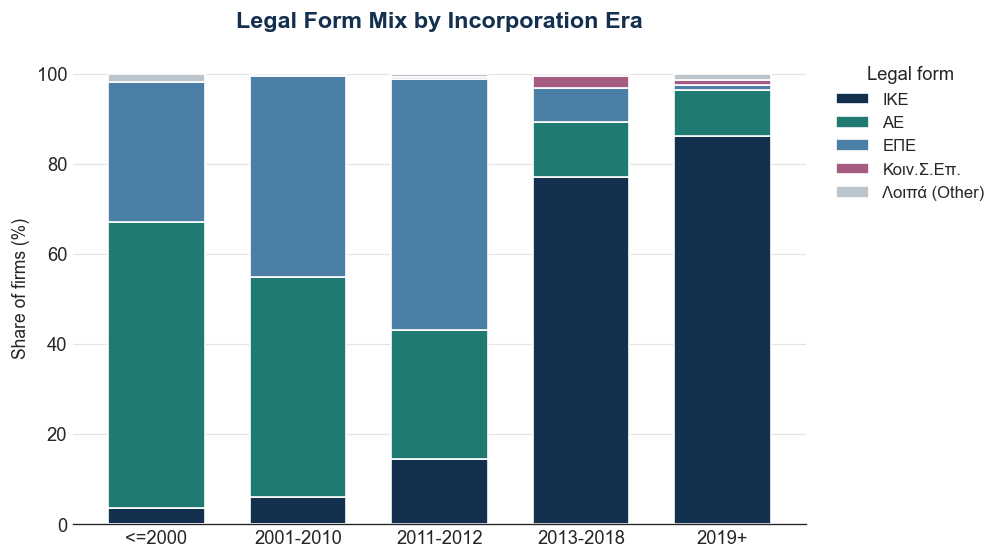

In [8]:
LEGAL_TOP_LABELS = [l for l in top_n_plus_other(df250["legalType"], n=4, report=False).index
                     if l not in (OTHER_LABEL, UNKNOWN)]
df250["legalType_bucketed"] = df250["legalType"].where(df250["legalType"].isin(LEGAL_TOP_LABELS), OTHER_LABEL)

df250["incorp_year"] = df250["incorporationDate"].dt.year
year_bins = pd.cut(df250["incorp_year"], bins=[1900, 2000, 2010, 2012, 2018, 2026],
                    labels=["<=2000", "2001-2010", "2011-2012", "2013-2018", "2019+"])
legal_by_era = pd.crosstab(year_bins, df250["legalType_bucketed"], normalize="index") * 100
legal_by_era = legal_by_era[[c for c in LEGAL_TOP_LABELS + [OTHER_LABEL] if c in legal_by_era.columns]]

fig, ax = plt.subplots(figsize=(8.5, 4.8))
legal_by_era.plot(kind="bar", stacked=True, ax=ax,
                   color=category_colors(legal_by_era.columns), width=0.68)
ax.set_title("Legal Form Mix by Incorporation Era")
ax.set_ylabel("Share of firms (%)")
ax.set_xlabel("")
ax.legend(title="Legal form", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
style_axis(ax, horizontal=False)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 6. Company Status

Full breakdown of `status` (active, deleted, dissolved/liquidated, merged out,
bankrupt, dormant, etc.), rather than collapsing straight to a binary active/inactive
flag -- the binary split hides that "inactive" is mostly ordinary deregistration
(`Διαγραφή`), not bankruptcy, which is worth seeing directly.

status: 15 missing values (0.0%) shown as 'Άγνωστο' below rather than dropped.


,count,pct
status,,
Ενεργή,173704,76.0
Διαγραφή,39981,17.5
Λύση - Εκκαθάριση,10730,4.7
Διαγραφή λόγω συγχώνευσης,2700,1.2
Πτώχευση,924,0.4
Άλλο,95,0.0
Λοιπά (Other),308,0.1


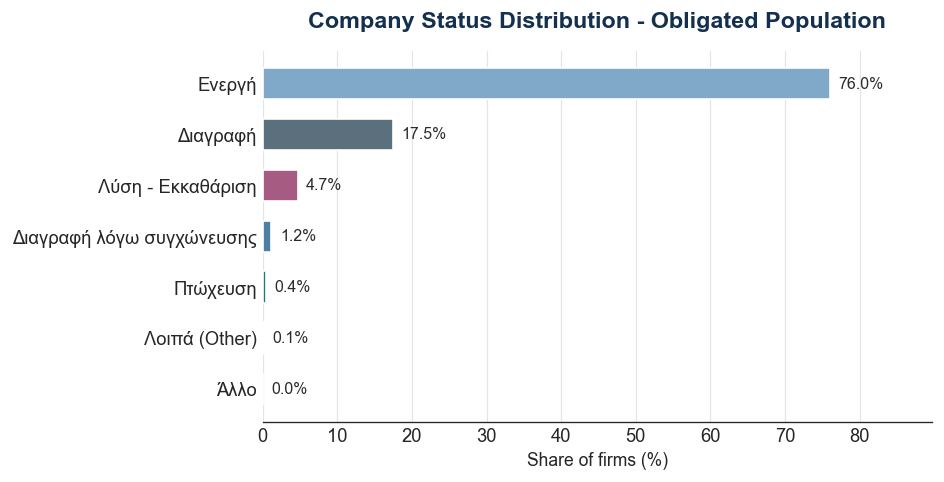

In [9]:
status_top = top_n_plus_other(df250["status"], n=6, name="status")
display(status_top.to_frame("count").assign(pct=lambda d: (d['count']/len(df250)*100).round(1)))

barh_pct(status_top, "Company Status Distribution - Obligated Population")
plt.show()

## 7. Regional Concentration

Attica prefectures (ΑΤΤΙΚΗΣ, ΑΘΗΝΩΝ, ΠΕΙΡΑΙΩΣ/ΠΕΙΡΑΙΑ, ΔΥΤΙΚΗΣ ΑΤΤΙΚΗΣ, ΑΝΑΤΟΛΙΚΗΣ
ΑΤΤΙΚΗΣ) were unified into one `ΑΤΤΙΚΗ` region group **immediately after loading the
data** (Section 3), before any preview or count touched the raw `prefecture` field --
running the merge later, after other analysis had already used the unmerged column,
is what previously caused Δωδεκάνησου to outrank Attica in a region ranking. All
analysis from this point on uses the already-unified `region_group`, matching the
treatment already applied to the primary 2,000-firm panel.

In [10]:
# region_group was already created right after data loading (Section 3) -- confirming
# here that it is present and the merge looks right before using it below.
assert "region_group" in df250.columns, "region_group missing -- check Section 3"
print(f"region_group already unified at load time. Distinct regions: {df250['region_group'].nunique()}")
print(df250["region_group"].value_counts().head(5))

region_group already unified at load time. Distinct regions: 53
region_group
ΑΤΤΙΚΗΣ         123331
ΘΕΣΣΑΛΟΝΙΚΗΣ     23073
ΗΡΑΚΛΕΙΟΥ         6623
ΑΧΑΙΑΣ            4826
ΚΥΚΛΑΔΩΝ          4430
Name: count, dtype: int64


,count,pct
region_group,,
ΑΤΤΙΚΗΣ,123331,54.0
ΘΕΣΣΑΛΟΝΙΚΗΣ,23073,10.1
ΗΡΑΚΛΕΙΟΥ,6623,2.9
ΑΧΑΙΑΣ,4826,2.1
ΚΥΚΛΑΔΩΝ,4430,1.9
ΔΩΔΕΚΑΝΗΣΟΥ,4320,1.9
ΛΑΡΙΣΑΣ,3649,1.6
ΚΕΡΚΥΡΑΣ,3058,1.3
Άγνωστο,3008,1.3


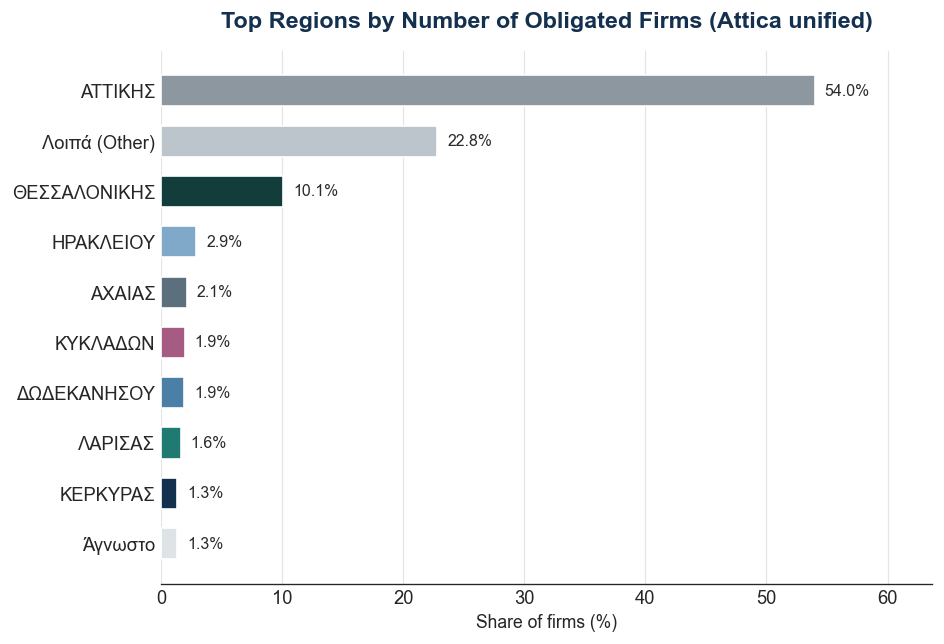

In [11]:
region_top = top_n_plus_other(df250["region_group"], n=9, name="region_group")
display(region_top.to_frame("count").assign(pct=lambda d: (d['count']/len(df250)*100).round(1)))

barh_pct(region_top, "Top Regions by Number of Obligated Firms (Attica unified)")
plt.show()

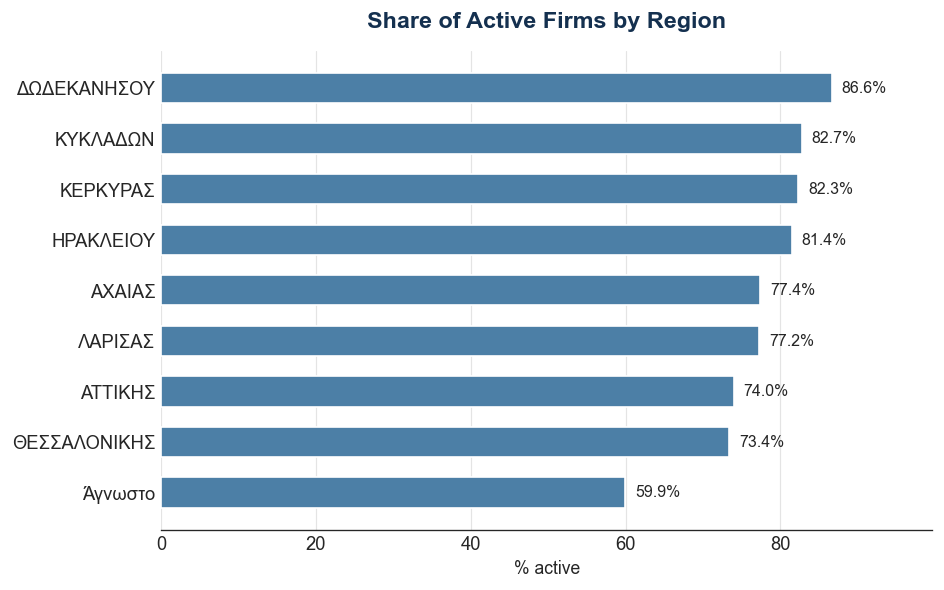

In [12]:
active_by_region = df250.groupby("region_group")[ACTIVE_COL].mean().mul(100)
top_region_labels = [l for l in region_top.index if l != OTHER_LABEL]
active_top = active_by_region.loc[active_by_region.index.isin(top_region_labels)].sort_values()

fig, ax = plt.subplots(figsize=(8, max(2.5, 0.45*len(active_top)+1)))
bars = ax.barh(active_top.index, active_top.values, color=STEEL, height=0.6)
xmax = max(active_top.values.max(), 1)
for b, v in zip(bars, active_top.values):
    ax.text(b.get_width() + xmax*0.015, b.get_y()+b.get_height()/2, f"{v:.1f}%", va="center", fontsize=9.5)
ax.set_xlim(0, min(105, xmax*1.15))
ax.set_title("Share of Active Firms by Region")
ax.set_xlabel("% active")
style_axis(ax, horizontal=True)
plt.tight_layout()
plt.show()

## 8. Sectoral Distribution (NACE Section)

`primary_activity` is a free-text ΚΑΔ description (thousands of near-unique values)
and is not usable directly for a sector chart; `primary_kad` is mapped to its NACE
Rev. 2 / ΣΤΑΚΟΔ 08 section (A–U) via the standard 2-digit-prefix ranges instead.

In [13]:
df250["nace_section"] = df250["primary_kad"].apply(kad_to_nace_section)
print(f"Distinct raw primary_kad codes: {df250['primary_kad'].nunique():,}")
print(f"Distinct NACE sections after mapping: {df250['nace_section'].nunique()}")

sector_counts = df250["nace_section"].value_counts()
display(sector_counts.to_frame("count").assign(pct=lambda d: (d['count']/len(df250)*100).round(1)))

Distinct raw primary_kad codes: 8,698
Distinct NACE sections after mapping: 20


,count,pct
nace_section,,
G - Χονδρικό/Λιανικό Εμπόριο,48947,21.4
"I - Καταλύματα, Εστίαση",26554,11.6
"M - Επιστημονικές, Τεχνικές Δραστ.",21623,9.5
F - Κατασκευές,18799,8.2
L - Διαχείριση Ακίνητης Περ.,18245,8.0
C - Μεταποίηση,17431,7.6
"D - Ηλεκτρισμός, Αέριο",14417,6.3
"J - Ενημέρωση, Επικοινωνία",11468,5.0
"H - Μεταφορά, Αποθήκευση",9961,4.4


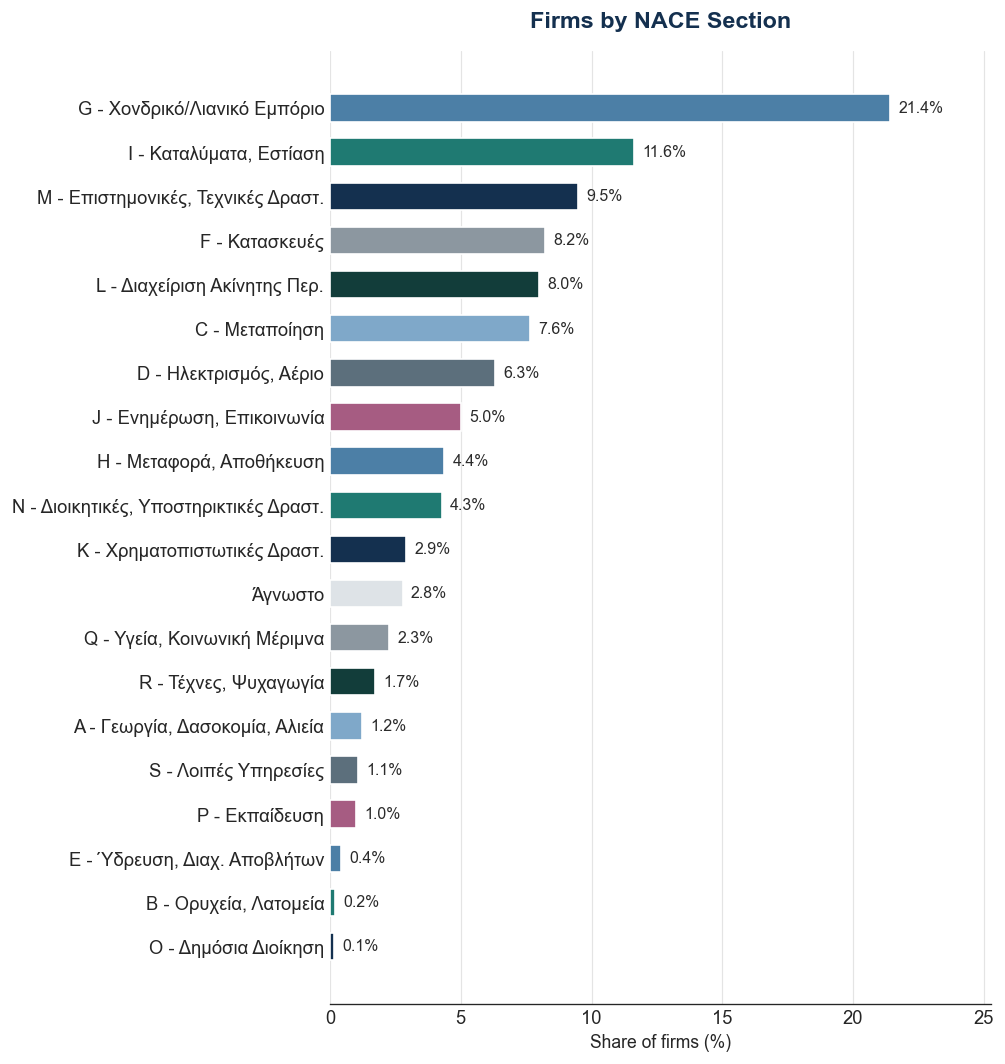

In [14]:
barh_pct(sector_counts, "Firms by NACE Section", figsize=(8.5, max(4, 0.4*len(sector_counts)+1)))
plt.show()

## 9. Firm-Age Distribution

Only the top legal forms/sectors are shown, to keep the boxplot legible; extreme
outliers (implausibly old firms) are reported separately rather than left to distort
the y-axis.

In [15]:
df250["firm_age_years"] = (TODAY - df250["incorporationDate"]).dt.days / 365.25
implausible = df250[df250["firm_age_years"] > 100]
print(f"Firms with implausible age (>100 years): {len(implausible)} "
      f"({len(implausible)/len(df250)*100:.2f}%) -- likely date-parsing artefacts; "
      f"spot-check a few against the raw export before trusting them.")
print(f"Median firm age: {df250['firm_age_years'].median():.1f} years | "
      f"95th percentile: {df250['firm_age_years'].quantile(0.95):.1f} years")

Firms with implausible age (>100 years): 118 (0.05%) -- likely date-parsing artefacts; spot-check a few against the raw export before trusting them.
Median firm age: 7.8 years | 95th percentile: 37.8 years


<temp>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x="legalType_bucketed", y="firm_age_years", ax=ax,


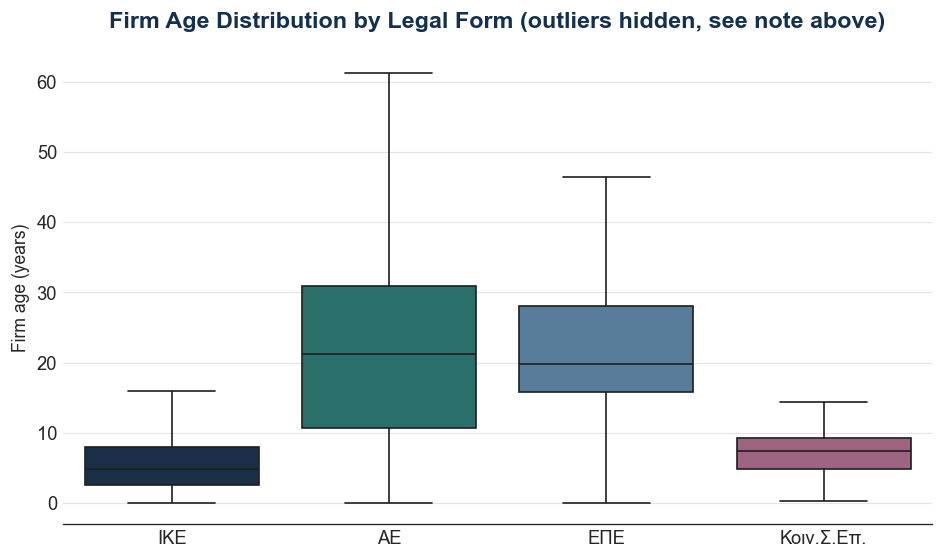

In [16]:
plot_df = df250[df250["legalType_bucketed"] != OTHER_LABEL]
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.boxplot(data=plot_df, x="legalType_bucketed", y="firm_age_years", ax=ax,
            palette=category_colors(LEGAL_TOP_LABELS), showfliers=False, order=LEGAL_TOP_LABELS)
ax.set_title("Firm Age Distribution by Legal Form (outliers hidden, see note above)")
ax.set_ylabel("Firm age (years)")
ax.set_xlabel("")
style_axis(ax, horizontal=False)
plt.tight_layout()
plt.show()

<temp>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df_sector, x="nace_section", y="firm_age_years", ax=ax,


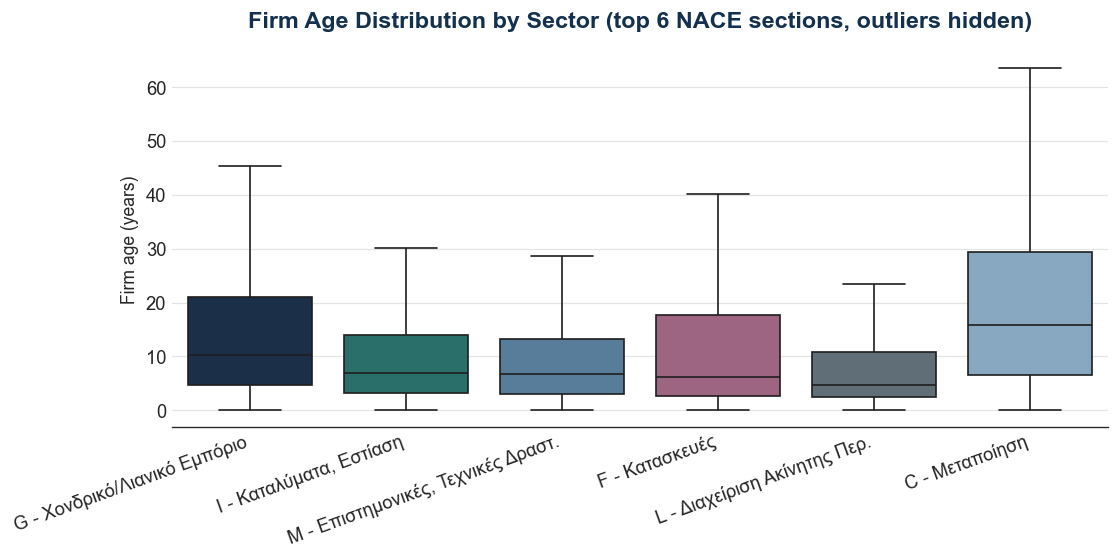

In [17]:
top_sectors = sector_counts.head(6).index.tolist()
plot_df_sector = df250[df250["nace_section"].isin(top_sectors)]
fig, ax = plt.subplots(figsize=(9.5, 4.8))
sns.boxplot(data=plot_df_sector, x="nace_section", y="firm_age_years", ax=ax,
            palette=category_colors(top_sectors), showfliers=False, order=top_sectors)
ax.set_title("Firm Age Distribution by Sector (top 6 NACE sections, outliers hidden)")
ax.set_ylabel("Firm age (years)")
ax.set_xlabel("")
style_axis(ax, horizontal=False)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 10. Activity Count and Registered Persons

`n_persons` reflects registered persons (owners, board members, authorised
signatories), **not** an employee count -- reported purely as a registry-composition
statistic, consistent with the primary thesis panel's treatment.

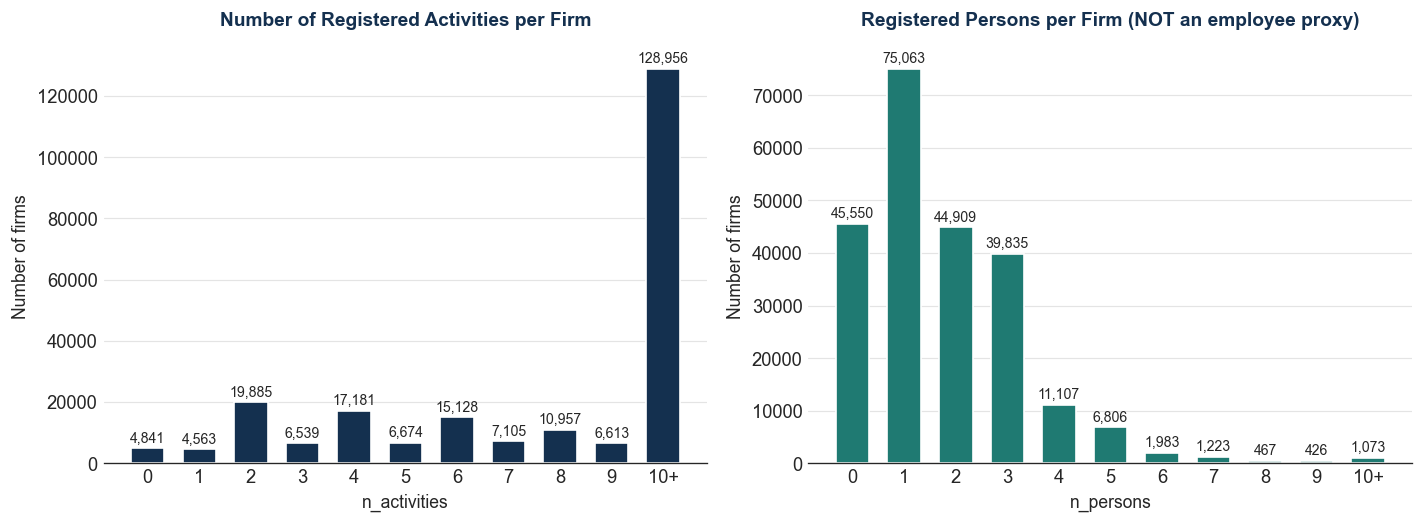

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, color, title in [
    (axes[0], "n_activities", NAVY, "Number of Registered Activities per Firm"),
    (axes[1], "n_persons", TEAL, "Registered Persons per Firm (NOT an employee proxy)"),
]:
    counts = df250[col].clip(upper=10).value_counts().sort_index()
    labels = [str(i) if i < 10 else "10+" for i in counts.index]
    bars = ax.bar(labels, counts.values, color=color, width=0.65)
    ymax = counts.values.max()
    for b, v in zip(bars, counts.values):
        ax.text(b.get_x()+b.get_width()/2, v + ymax*0.015, f"{v:,}", ha="center", fontsize=8.5)
    ax.set_title(title, fontsize=11.5)
    ax.set_xlabel(col)
    ax.set_ylabel("Number of firms")
    style_axis(ax, horizontal=False)
plt.tight_layout()
plt.show()

## 11. Panel-Eligibility Funnel

The full sampling chain, from the entire ΓΕΜΗ registry down to the primary panel:
the registry-wide total (1,686,552, queried directly via the Open Data API's
unfiltered company search) replaces the earlier `[VERIFY]`-flagged estimate in the
thesis text with a confirmed figure. The last three stages -- obligated population,
eligible pool, and primary panel -- are the ones compared throughout Section 12.

0. Total companies in the ΓΕΜΗ registry:        1,686,552
1. Financial-statement-obligated firms:         228,442 (13.5% of the full registry)
2. Firms with 10 consecutive years of filings:  3,938 (1.72% of obligated population)
3. Randomly sampled into the primary panel:     2,000 (50.8% of the eligible pool)


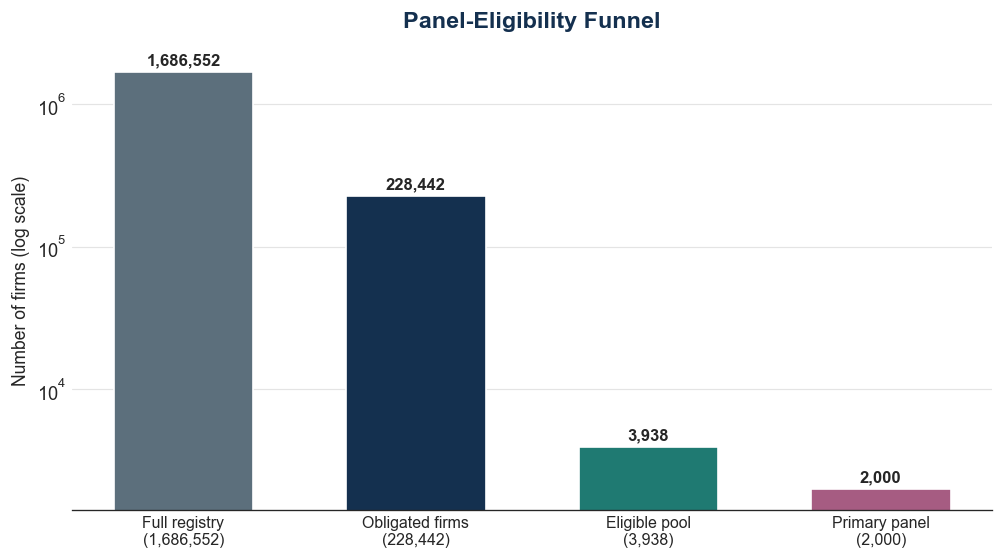

In [19]:
n_total_registry = 1_686_552  # queried directly via GEMI Open Data API, unfiltered company search
n_total_obligated = len(df250)
n_full_history = int(df250["meets_threshold"].sum())
n_primary_panel = 2000

print(f"0. Total companies in the ΓΕΜΗ registry:        {n_total_registry:,}")
print(f"1. Financial-statement-obligated firms:         {n_total_obligated:,} "
      f"({n_total_obligated / n_total_registry * 100:.1f}% of the full registry)")
print(f"2. Firms with 10 consecutive years of filings:  {n_full_history:,} "
      f"({n_full_history / n_total_obligated * 100:.2f}% of obligated population)")
print(f"3. Randomly sampled into the primary panel:     {n_primary_panel:,} "
      f"({n_primary_panel / n_full_history * 100:.1f}% of the eligible pool)")

funnel_labels = [f"Full registry\n({n_total_registry:,})",
                  f"Obligated firms\n({n_total_obligated:,})",
                  f"Eligible pool\n({n_full_history:,})",
                  f"Primary panel\n({n_primary_panel:,})"]
funnel_values = [n_total_registry, n_total_obligated, n_full_history, n_primary_panel]
funnel_colors = [SLATE, STAGE_COLORS["population"], STAGE_COLORS["eligible"], STAGE_COLORS["panel"]]

fig, ax = plt.subplots(figsize=(8.5, 4.8))
bars = ax.bar(funnel_labels, funnel_values, color=funnel_colors, width=0.6)
ax.set_yscale("log")
ax.set_title("Panel-Eligibility Funnel")
ax.set_ylabel("Number of firms (log scale)")
for b, v in zip(bars, funnel_values):
    ax.text(b.get_x()+b.get_width()/2, v*1.12, f"{v:,}", ha="center", fontweight="bold", fontsize=10)
style_axis(ax, horizontal=False)
plt.xticks(fontsize=9.5)
plt.tight_layout()
plt.show()

## 12. External Validity: Comparing All Three Funnel Stages

The strongest version of the "no selection bias" argument is not just population vs.
final panel -- it's checking that distributions stay stable **across every stage of
the funnel**: population (~ 228k) -> eligible pool (~3,900, the 10-year-filing
survivors) -> primary panel (2,000, the random draw from that pool). If the eligible
pool already looks like the population, and the panel looks like the eligible pool,
that is direct evidence that (a) the 10-year-filing requirement is not itself
introducing a sector/region/legal-form skew, and (b) the random sampling step did not
introduce a further one on top.

In [20]:
try:
    df2k = pd.read_csv(PRIMARY_PANEL_CSV, dtype={"gemh_id": str, "afm": str, "primary_kad": str},
                        low_memory=False)
    df2k_firms = df2k.drop_duplicates(subset="gemh_id").copy()
    df2k_firms["nace_section"] = df2k_firms["primary_kad"].apply(kad_to_nace_section) \
        if "primary_kad" in df2k_firms.columns else UNKNOWN
    if "prefecture" in df2k_firms.columns:
        df2k_firms["region_group"] = df2k_firms["prefecture"].apply(unify_attica)
    print(f"Loaded real primary panel: {df2k_firms.shape[0]} unique firms")
    comparison_source = "real 2,000-firm panel"
except FileNotFoundError:
    print("Primary panel CSV not found -- drawing a synthetic surrogate (pipeline-testing only).")
    df2k_firms = df250[df250["meets_threshold"]].sample(
        n=min(2000, n_full_history), random_state=RANDOM_STATE).copy()
    comparison_source = "synthetic surrogate"

df_eligible = df250[df250["meets_threshold"]].copy()
print(f"Eligible pool (10-year filers): {len(df_eligible):,} firms")
print(f"Comparison source for the primary panel stage: {comparison_source}")

Loaded real primary panel: 2000 unique firms
Eligible pool (10-year filers): 3,938 firms
Comparison source for the primary panel stage: real 2,000-firm panel


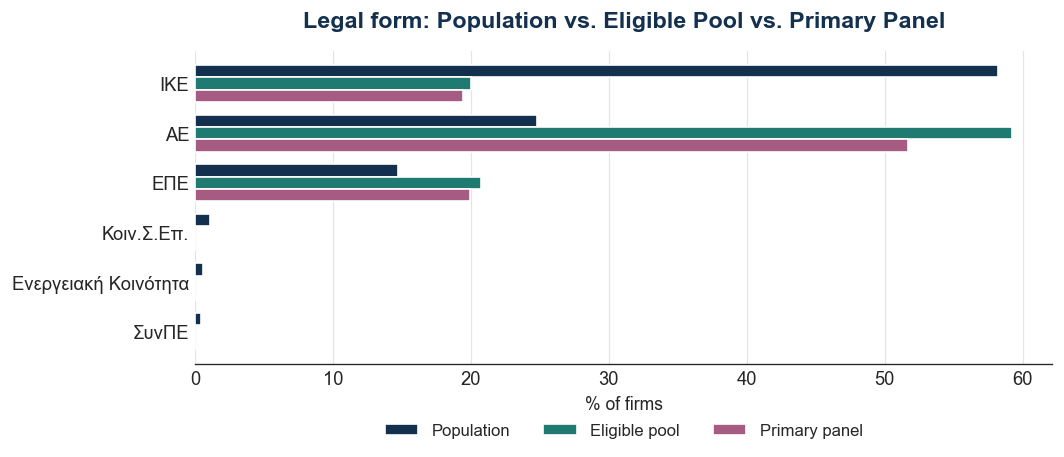

,Population,Eligible pool,Primary panel,max_gap_pp
legalType,,,,
ΙΚΕ,58.2,20.0,19.4,38.8
ΑΕ,24.8,59.2,51.7,34.4
ΕΠΕ,14.7,20.7,19.9,6.0
Κοιν.Σ.Επ.,1.1,0.0,0.0,1.1
Ενεργειακή Κοινότητα,0.6,0.0,0.0,0.6
ΣυνΠΕ,0.4,0.0,0.0,0.4


Largest population-vs-panel gap for any legal form category: 38.8 pp


In [21]:
def compare_three_stages(col_pop, col_elig, col_panel, label, top_n=6):
    """dtype-safe three-way comparison across population / eligible pool / primary
    panel, shown as a grouped horizontal bar chart in the shared stage colours."""
    def dist(s):
        s = s.fillna(UNKNOWN).astype(str)
        return (s.value_counts(normalize=True) * 100).round(1)

    pop_d, elig_d, panel_d = dist(col_pop), dist(col_elig), dist(col_panel)
    top_cats = pop_d.head(top_n).index.tolist()

    comp = pd.DataFrame({
        "Population": pop_d.reindex(top_cats).fillna(0),
        "Eligible pool": elig_d.reindex(top_cats).fillna(0),
        "Primary panel": panel_d.reindex(top_cats).fillna(0),
    })
    comp["max_gap_pp"] = comp.max(axis=1) - comp.min(axis=1)
    comp = comp.sort_values("max_gap_pp", ascending=False)

    fig, ax = plt.subplots(figsize=(9, max(3, 0.55*len(comp)+1)))
    y = np.arange(len(comp))
    h = 0.25
    ax.barh(y - h, comp["Population"], height=h, color=STAGE_COLORS["population"], label="Population")
    ax.barh(y, comp["Eligible pool"], height=h, color=STAGE_COLORS["eligible"], label="Eligible pool")
    ax.barh(y + h, comp["Primary panel"], height=h, color=STAGE_COLORS["panel"], label="Primary panel")
    ax.set_yticks(y)
    ax.set_yticklabels(comp.index)
    ax.invert_yaxis()
    ax.set_title(f"{label}: Population vs. Eligible Pool vs. Primary Panel")
    ax.set_xlabel("% of firms")
    ax.legend(frameon=False, loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.14))
    style_axis(ax, horizontal=True)
    plt.tight_layout(rect=[0, 0.06, 1, 1])
    plt.show()

    display(comp.round(1))
    max_overall_gap = comp["max_gap_pp"].max()
    print(f"Largest population-vs-panel gap for any {label.lower()} category: {max_overall_gap:.1f} pp")
    return comp

legal_col_2k = "legalType" if "legalType" in df2k_firms.columns else None
if legal_col_2k:
    compare_three_stages(df250["legalType"], df_eligible["legalType"], df2k_firms[legal_col_2k], "Legal form")

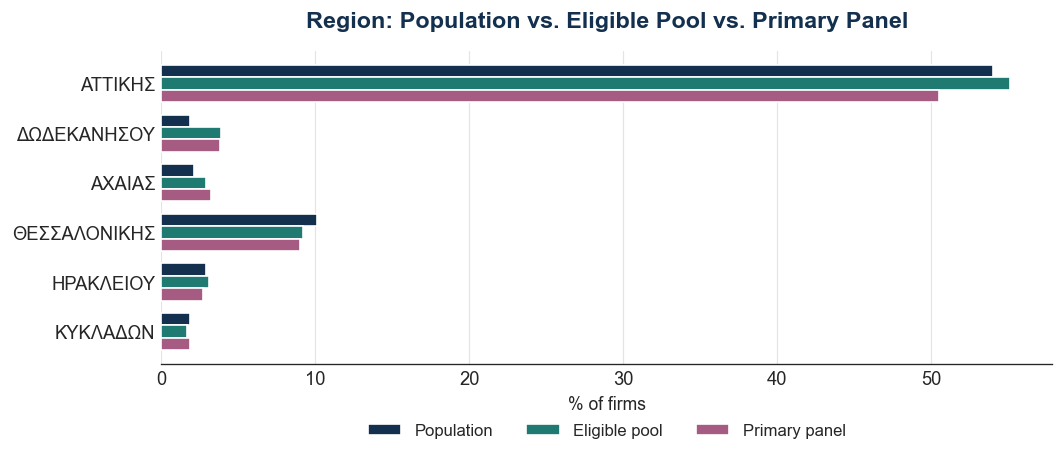

,Population,Eligible pool,Primary panel,max_gap_pp
region_group,,,,
ΑΤΤΙΚΗΣ,54.0,55.1,50.5,4.6
ΔΩΔΕΚΑΝΗΣΟΥ,1.9,3.9,3.8,2.0
ΑΧΑΙΑΣ,2.1,2.9,3.2,1.1
ΘΕΣΣΑΛΟΝΙΚΗΣ,10.1,9.2,9.0,1.1
ΗΡΑΚΛΕΙΟΥ,2.9,3.1,2.7,0.4
ΚΥΚΛΑΔΩΝ,1.9,1.7,1.9,0.2


Largest population-vs-panel gap for any region category: 4.6 pp


In [22]:
if "region_group" in df2k_firms.columns:
    compare_three_stages(df250["region_group"], df_eligible["region_group"],
                          df2k_firms["region_group"], "Region")
else:
    print("No region_group column in the primary panel -- skipped.")

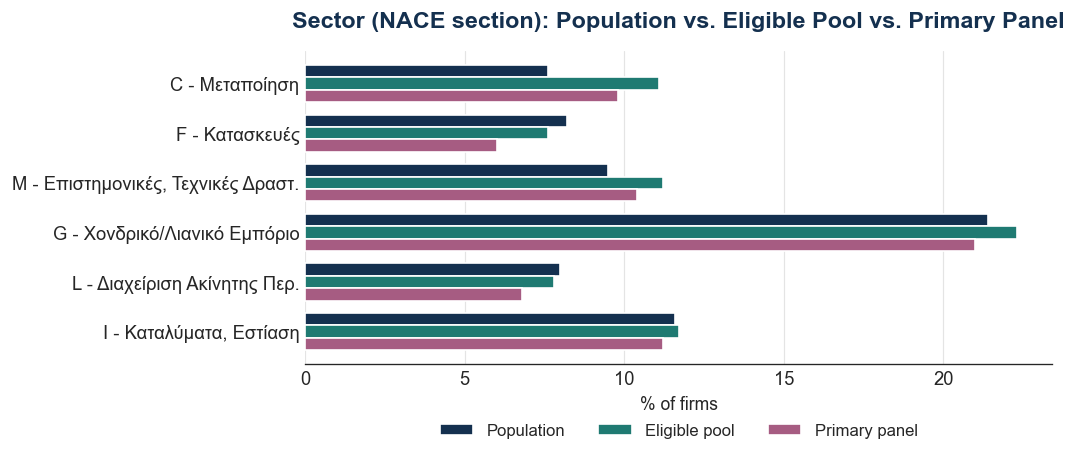

,Population,Eligible pool,Primary panel,max_gap_pp
nace_section,,,,
C - Μεταποίηση,7.6,11.1,9.8,3.5
F - Κατασκευές,8.2,7.6,6.0,2.2
"M - Επιστημονικές, Τεχνικές Δραστ.",9.5,11.2,10.4,1.7
G - Χονδρικό/Λιανικό Εμπόριο,21.4,22.3,21.0,1.3
L - Διαχείριση Ακίνητης Περ.,8.0,7.8,6.8,1.2
"I - Καταλύματα, Εστίαση",11.6,11.7,11.2,0.5


Largest population-vs-panel gap for any sector (nace section) category: 3.5 pp

INTERPRETATION: small, stable gaps (a few percentage points) across all three funnel stages and all three dimensions support the claim that neither the 10-year-filing requirement nor the random sampling step introduced a meaningful sector/region/legal-form skew. A category that jumps sharply between stages (not just population-vs-panel, but specifically at the population-to-eligible-pool step) would indicate the survivorship filter itself is selective on that dimension, which would need to be reported as a limitation in Chapter 7 regardless of what the final random draw looks like.


In [23]:
compare_three_stages(df250["nace_section"], df_eligible["nace_section"],
                      df2k_firms["nace_section"], "Sector (NACE section)")

print("\nINTERPRETATION: small, stable gaps (a few percentage points) across all three "
      "funnel stages and all three dimensions support the claim that neither the "
      "10-year-filing requirement nor the random sampling step introduced a "
      "meaningful sector/region/legal-form skew. A category that jumps sharply "
      "between stages (not just population-vs-panel, but specifically at the "
      "population-to-eligible-pool step) would indicate the survivorship filter "
      "itself is selective on that dimension, which would need to be reported as a "
      "limitation in Chapter 7 regardless of what the final random draw looks like.")

## 13. Summary for Thesis Section 5.5

In [24]:
print("="*70)
print("SUMMARY -- Section 5.5 External Validity")
print("="*70)
print(f"Population (financial-statement-obligated firms):  {n_total_obligated:,}")
print(f"Eligible pool (10-year filing history):             {n_full_history:,} "
      f"({n_full_history/n_total_obligated*100:.2f}%)")
print(f"Primary thesis panel (randomly sampled):             {n_primary_panel:,}")
print()
print("Top legal form:", legal_top.index[0], f"({legal_top.iloc[0]/len(df250)*100:.1f}% of population)")
print("Top status:", status_top.index[0], f"({status_top.iloc[0]/len(df250)*100:.1f}% of population)")
print("Top region:", region_top.index[0], f"({region_top.iloc[0]/len(df250)*100:.1f}% of population)")
print("Top sector:", sector_counts.index[0], f"({sector_counts.iloc[0]/len(df250)*100:.1f}% of population)")
print()
print(f"Comparison source used for the primary-panel stage: {comparison_source}")
print()
print("Reminder: this run used", "SYNTHETIC" if USE_SYNTHETIC else "REAL", "data.")

SUMMARY -- Section 5.5 External Validity
Population (financial-statement-obligated firms):  228,442
Eligible pool (10-year filing history):             3,938 (1.72%)
Primary thesis panel (randomly sampled):             2,000

Top legal form: ΙΚΕ (58.2% of population)
Top status: Ενεργή (76.0% of population)
Top region: ΑΤΤΙΚΗΣ (54.0% of population)
Top sector: G - Χονδρικό/Λιανικό Εμπόριο (21.4% of population)

Comparison source used for the primary-panel stage: real 2,000-firm panel

Reminder: this run used REAL data.


In [26]:
# Export of objects used by thesis_tables.ipynb
import pickle

_panel_cols = [c for c in ["gemh_id", "legalType", "region_group", "nace_section"] if c in df2k_firms.columns]
EXPORT_PATH = "thesis_objects.pkl"   # the same file as in ml_profitability_notebook_v14 (give the full path if the folder differs)
REG_EXPORT = {
    "n_registry": n_total_registry,
    "population": df250[["arGemi", "legalType", "status", "region_group", "nace_section"]].copy(),
    "pool": df_eligible[["arGemi", "legalType", "region_group", "nace_section"]].copy(),
    "panel": df2k_firms[_panel_cols].copy(),
    "UNKNOWN": UNKNOWN, "OTHER_LABEL": OTHER_LABEL,
}
try:
    with open(EXPORT_PATH, "rb") as _f:
        _all = pickle.load(_f)
except FileNotFoundError:
    _all = {}
_all["registry"] = REG_EXPORT
with open(EXPORT_PATH, "wb") as _f:
    pickle.dump(_all, _f)
print(f"Added the registry part to {EXPORT_PATH}; main notebook part included: {'ml_df' in _all}")

Added the registry part to thesis_objects.pkl; main notebook part included: False
